# Análisis de carteras

Construcción y comparación de carteras a partir de precios de mercado: qué
rentabilidad ofrecen, cuánto riesgo asumen y de dónde sale ese riesgo.

El notebook intenta descargar datos reales de Yahoo Finance. Si no hay salida a
internet, pasa automáticamente a datos simulados y lo avisa por pantalla: los
métodos se ven igual, pero las conclusiones concretas sólo valen con datos reales.

In [1]:
import warnings

import numpy as np
import pandas as pd

from icm import graficos
from icm.cartera import (
    Restricciones,
    cartera_pesos_iguales,
    comparar_carteras,
    contribuciones_riesgo,
    frontera_eficiente,
    linea_mercado_capitales,
    maximo_sharpe,
    minima_varianza,
    paridad_riesgo,
    resumen_metricas,
    volatilidad_cartera,
)
from icm.datos import cargar_precios, matriz_covarianzas, rendimientos, rendimientos_cartera

graficos.aplicar_estilo()
pd.set_option("display.precision", 4)
pd.set_option("display.width", 140)

In [2]:
TICKERS = ["AAPL", "MSFT", "JNJ", "XOM", "JPM"]
INICIO, FIN = "2018-01-01", "2024-12-31"

with warnings.catch_warnings(record=True) as avisos:
    warnings.simplefilter("always")
    precios = cargar_precios(TICKERS, INICIO, FIN, respaldo_simulado=True)

DATOS_SIMULADOS = any("SIMULADOS" in str(a.message) for a in avisos)
if DATOS_SIMULADOS:
    print("!! Sin acceso a Yahoo Finance: se trabaja con DATOS SIMULADOS.")
    print("   Las cifras ilustran los metodos, no describen el mercado real.\n")
else:
    print(f"Datos reales de Yahoo Finance: {len(precios)} sesiones.\n")

rend = rendimientos(precios, "log")
precios.tail(3).round(2)

Datos reales de Yahoo Finance: 1760 sesiones.



,AAPL,MSFT,JNJ,XOM,JPM
fecha,,,,,
2024-12-26,257.15,432.16,139.02,100.70,234.77
2024-12-27,253.75,424.68,138.51,100.69,232.86
2024-12-30,250.38,419.06,136.88,100.01,231.08


## 1. Qué tenemos entre manos

Antes de optimizar nada conviene mirar los datos. Dos preguntas: cómo se han
comportado los activos y hasta qué punto se mueven juntos, porque de eso depende
todo lo que viene después.

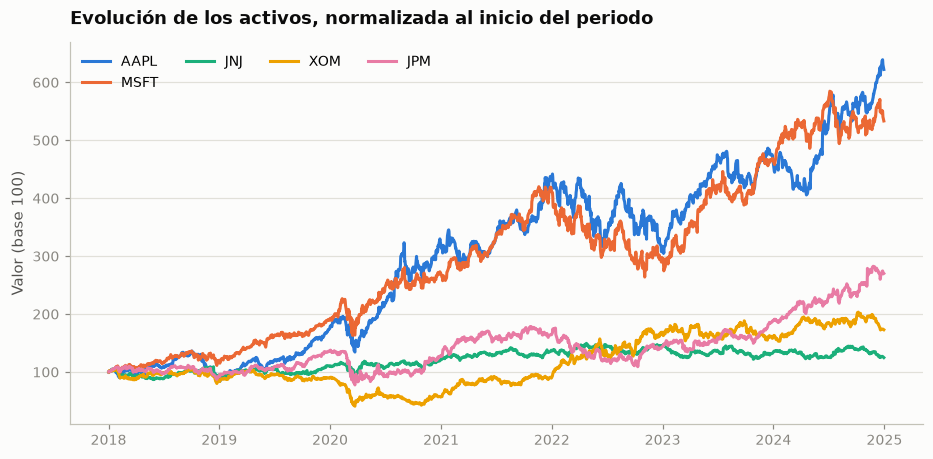

In [3]:
base_100 = precios / precios.iloc[0] * 100
figura, ax = graficos.series_temporales(
    {columna: base_100[columna] for columna in base_100.columns},
    etiqueta_y="Valor (base 100)",
)
ax.set_title("Evolución de los activos, normalizada al inicio del periodo");

In [4]:
metricas = pd.DataFrame(
    {activo: resumen_metricas(rend[activo]) for activo in rend.columns}
).T
metricas[
    [
        "rentabilidad_anualizada",
        "volatilidad_anualizada",
        "ratio_sharpe",
        "maxima_caida",
        "asimetria",
        "curtosis_exceso",
    ]
].round(3)

,rentabilidad_anualizada,volatilidad_anualizada,ratio_sharpe,maxima_caida,asimetria,curtosis_exceso
AAPL,0.299,0.306,0.980,-0.385,-0.216,5.276
MSFT,0.271,0.289,0.938,-0.371,-0.267,7.173
JNJ,0.032,0.196,0.165,-0.274,-0.411,9.498
XOM,0.082,0.310,0.263,-0.610,-0.170,5.509
JPM,0.153,0.295,0.518,-0.436,-0.019,13.483


In [5]:
correlacion = rend.corr()
print("Correlación media entre pares:", round(
    correlacion.to_numpy()[~np.eye(len(correlacion), dtype=bool)].mean(), 3
))
correlacion.round(2)

Correlación media entre pares: 0.419


,AAPL,MSFT,JNJ,XOM,JPM
AAPL,1.00,0.73,0.35,0.31,0.43
MSFT,0.73,1.00,0.38,0.28,0.44
JNJ,0.35,0.38,1.00,0.31,0.39
XOM,0.31,0.28,0.31,1.00,0.57
JPM,0.43,0.44,0.39,0.57,1.00


## 2. Cuatro formas de repartir el dinero

Cada cartera responde a una filosofía distinta:

| Cartera | Qué optimiza | Qué estima |
|---|---|---|
| **1/N** | nada: reparte el capital a partes iguales | nada |
| **Mínima varianza** | la volatilidad total | sólo covarianzas |
| **Máximo Sharpe** | la rentabilidad por unidad de riesgo | covarianzas **y** rentabilidades esperadas |
| **Paridad de riesgo** | que cada activo aporte el mismo riesgo | sólo covarianzas |

La distinción importante es la última columna. Estimar rentabilidades esperadas a
partir del pasado es mucho más ruidoso que estimar covarianzas, y por eso la
cartera de máximo Sharpe, que parece la más sofisticada, suele ser la más frágil
fuera de muestra. Lo comprobamos en la sección 5.

In [6]:
mu = rend.mean() * 252                        # rentabilidad esperada anual
cov = matriz_covarianzas(rend, anualizar=True)
TASA_SIN_RIESGO = 0.02

restricciones = Restricciones(permitir_cortos=False, peso_maximo=0.40)

carteras = {
    "1/N": cartera_pesos_iguales(rend.columns),
    "Mínima varianza": minima_varianza(cov, restricciones),
    "Máximo Sharpe": maximo_sharpe(mu, cov, TASA_SIN_RIESGO, restricciones),
    "Paridad de riesgo": paridad_riesgo(cov),
}
pd.DataFrame(carteras).round(3)

,1/N,Mínima varianza,Máximo Sharpe,Paridad de riesgo
AAPL,0.2,0.098,0.4,0.169
MSFT,0.2,0.192,0.4,0.178
JNJ,0.2,0.400,0.0,0.295
XOM,0.2,0.201,0.0,0.185
JPM,0.2,0.108,0.2,0.173


In [7]:
comparacion = comparar_carteras(carteras, mu, cov, TASA_SIN_RIESGO)
comparacion.round(4)

,rentabilidad,volatilidad,sharpe,activos_con_peso,peso_maximo
1/N,0.1509,0.2061,0.6352,5.0,0.200
Mínima varianza,0.1158,0.1877,0.5106,5.0,0.400
Máximo Sharpe,0.2292,0.2544,0.8225,3.0,0.400
Paridad de riesgo,0.1355,0.1964,0.5882,5.0,0.295


## 3. La frontera eficiente

Cada punto de la curva es la cartera de menor volatilidad posible para una
rentabilidad dada. Nada de lo que está por debajo y a la derecha tiene sentido:
existe otra cartera con la misma rentabilidad y menos riesgo.

La recta discontinua es la línea del mercado de capitales, que une el activo sin
riesgo con la cartera tangente. Su pendiente es el mejor ratio de Sharpe
alcanzable; más allá del punto de tangencia se está invirtiendo con dinero
prestado.

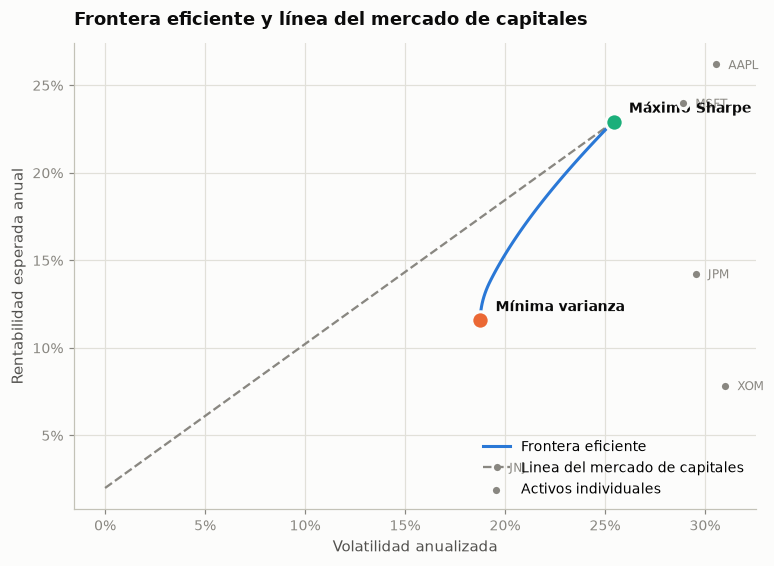

In [8]:
frontera = frontera_eficiente(mu, cov, n_puntos=60, restricciones=restricciones, incluir_pesos=False)
recta, tangente = linea_mercado_capitales(
    mu, cov, TASA_SIN_RIESGO, volatilidad_maxima=float(frontera["volatilidad"].max()),
    restricciones=restricciones,
)

figura, ax = graficos.frontera_eficiente(
    frontera,
    carteras={
        nombre: (volatilidad_cartera(pesos, cov), float(pesos @ mu))
        for nombre, pesos in carteras.items()
        if nombre in {"Mínima varianza", "Máximo Sharpe"}
    },
    activos={
        activo: (float(np.sqrt(cov.loc[activo, activo])), float(mu[activo]))
        for activo in rend.columns
    },
    recta=recta,
)
ax.set_title("Frontera eficiente y línea del mercado de capitales");

## 4. Repartir el capital no es repartir el riesgo

La cartera 1/N da a todos los activos el mismo peso en euros. Eso no significa
que todos aporten lo mismo al riesgo: el activo más volátil y más correlacionado
con el resto acaba dominando.

La descomposición se apoya en el teorema de Euler: como la volatilidad es
homogénea de grado uno en los pesos, las contribuciones suman exactamente la
volatilidad total, sin residuo.

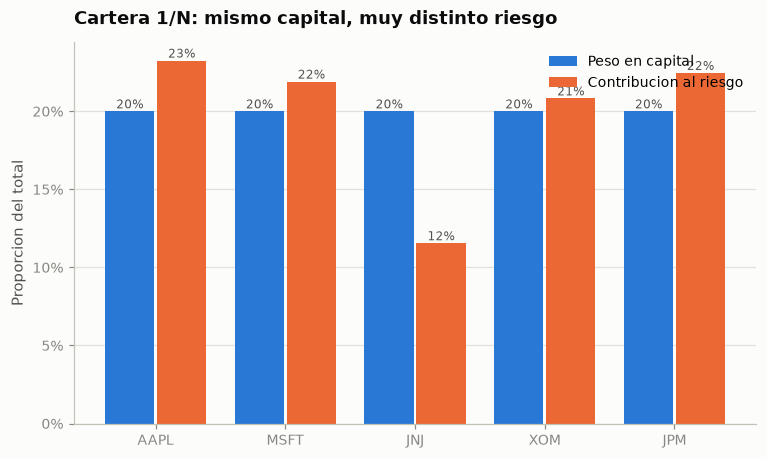

In [9]:
tabla_1n = contribuciones_riesgo(carteras["1/N"], cov)
figura, ax = graficos.contribuciones_riesgo(tabla_1n)
ax.set_title("Cartera 1/N: mismo capital, muy distinto riesgo");

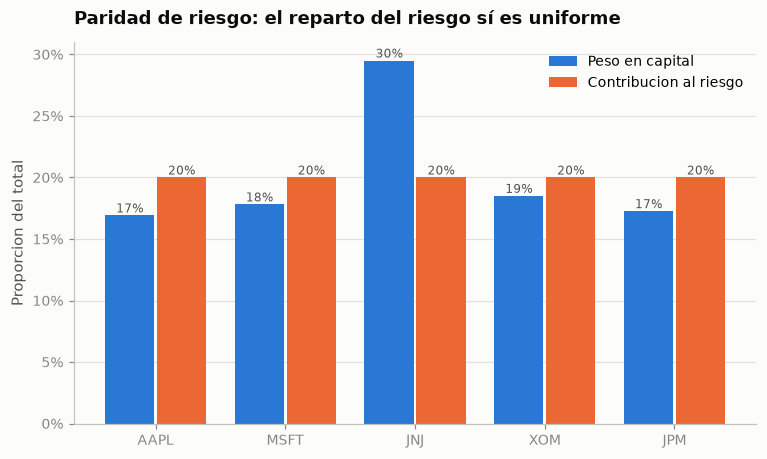

In [10]:
tabla_paridad = contribuciones_riesgo(carteras["Paridad de riesgo"], cov)
figura, ax = graficos.contribuciones_riesgo(tabla_paridad)
ax.set_title("Paridad de riesgo: el reparto del riesgo sí es uniforme");

## 5. La prueba que de verdad importa: fuera de muestra

Comparar carteras sobre los mismos datos con los que se han optimizado no dice
nada. La de máximo Sharpe siempre ganará ahí, por construcción.

La prueba honesta es partir la muestra: estimar con la primera mitad y evaluar
con la segunda, que el optimizador no ha visto.

In [11]:
corte = len(rend) // 2
dentro, fuera = rend.iloc[:corte], rend.iloc[corte:]

mu_dentro = dentro.mean() * 252
cov_dentro = matriz_covarianzas(dentro, anualizar=True)

carteras_dentro = {
    "1/N": cartera_pesos_iguales(dentro.columns),
    "Mínima varianza": minima_varianza(cov_dentro, restricciones),
    "Máximo Sharpe": maximo_sharpe(mu_dentro, cov_dentro, TASA_SIN_RIESGO, restricciones),
    "Paridad de riesgo": paridad_riesgo(cov_dentro),
}

filas = {}
for nombre, pesos in carteras_dentro.items():
    serie_fuera = rendimientos_cartera(fuera, pesos)
    resumen = resumen_metricas(serie_fuera, TASA_SIN_RIESGO)
    filas[nombre] = resumen[
        ["rentabilidad_anualizada", "volatilidad_anualizada", "ratio_sharpe", "maxima_caida"]
    ]

fuera_de_muestra = pd.DataFrame(filas).T
fuera_de_muestra.round(4)

,rentabilidad_anualizada,volatilidad_anualizada,ratio_sharpe,maxima_caida
1/N,0.1575,0.1574,0.8732,-0.1455
Mínima varianza,0.1159,0.1400,0.6855,-0.1143
Máximo Sharpe,0.1518,0.2043,0.6450,-0.2530
Paridad de riesgo,0.1403,0.1490,0.8071,-0.1370


In [12]:
print(f"Periodo de estimación: {dentro.index[0].date()} a {dentro.index[-1].date()}")
print(f"Periodo de evaluación: {fuera.index[0].date()} a {fuera.index[-1].date()}\n")
mejor_sharpe = fuera_de_muestra["ratio_sharpe"].idxmax()
menos_volatil = fuera_de_muestra["volatilidad_anualizada"].idxmin()
print(f"Mejor Sharpe fuera de muestra: {mejor_sharpe}")
print(f"Menor volatilidad fuera de muestra: {menos_volatil}")

Periodo de estimación: 2018-01-03 a 2021-06-30
Periodo de evaluación: 2021-07-01 a 2024-12-30

Mejor Sharpe fuera de muestra: 1/N
Menor volatilidad fuera de muestra: Mínima varianza


## 6. Qué llevarse de aquí

1. **La diversificación se mide en riesgo, no en capital.** La cartera 1/N parece
   equilibrada y rara vez lo está; la descomposición de la sección 4 lo hace
   visible de un vistazo.
2. **Cuantos más parámetros estima una cartera, más frágil es.** Mínima varianza y
   paridad de riesgo sólo necesitan covarianzas; máximo Sharpe necesita además
   rentabilidades esperadas, que es justo lo que peor se estima.
3. **Las restricciones no son un estorbo, son regularización.** Prohibir los cortos
   y poner un tope por activo impide que el optimizador concentre la cartera en el
   activo con el error de estimación más favorable.
4. Un análisis completo necesita, además, el riesgo de cola: la volatilidad no dice
   nada sobre lo que ocurre los peores días. Eso es el segundo notebook.